# 03 · Contact policy: whom to call, how many times, and how to prove it works

**Summary.** The published attempt-cap numbers reproduce exactly: capping at five calls saves 14.6% of calls and keeps
96.0% of subscriptions. Every call month from July 2008 is scored by a model trained only on earlier months (29,051
contacts). On those scores the propensity model ranks weakly within a monthly list (AUC 0.57), and its probability
level fails at regime turns (82% predicted vs 5% observed in November 2008). Under illustrative economics (EUR 100 margin, EUR 5 per call), every policy beats calling
everyone uncapped: the cap at five adds EUR 31k, an expected-value floor plus the cap EUR 59k. But almost all of that
gain sits in July-December 2008, when the average client converted at 5.9% after 2.8 calls and lost money, so any
policy that called less won. In the 2009-10 high-conversion regime, calling fewer people loses money. The
recommendation: keep the cap at five (it gains in 10 of 12 cost scenarios); size each campaign wave from its first
week of observed conversion; use the score to order calls, not to cut clients; and prove it with a randomised 80/20
holdout.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

import json, time
import lightgbm as lgb
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
T0 = time.perf_counter()

## 1. Reproduce the published attempt-cap numbers

The report's simulation is exact because `campaign` counts every call to the client in the campaign, including the
last: capping at N saves every call after the N-th, and loses every subscriber who said yes after call N.

In [2]:
df = F.load()
y = df[F.TARGET].to_numpy()
caps = pd.DataFrame([F.cap_effect(df["campaign"], y, c) for c in range(1, 16)]).set_index("cap")
c5 = caps.loc[5]
assert round(c5["calls_saved_pct"], 2) == 0.15 and round(c5["subscriptions_kept_pct"], 2) == 0.96
print(f"Cap at 5 (published: 15% fewer calls, 96% of subscriptions kept): {c5['calls_saved_pct']:.1%} of calls saved "
      f"({int(c5['calls_saved']):,} of {int(c5['calls']):,}), {c5['subscriptions_kept_pct']:.1%} of subscriptions kept ({int(c5['subscriptions_lost'])} lost)")
caps[["calls_saved", "calls_saved_pct", "subscriptions_lost", "subscriptions_kept_pct"]].loc[[2, 3, 4, 5, 6, 8, 10]]

Cap at 5 (published: 15% fewer calls, 96% of subscriptions kept): 14.6% of calls saved (15,425 of 105,754), 96.0% of subscriptions kept (186 lost)


,calls_saved,calls_saved_pct,subscriptions_lost,subscriptions_kept_pct
cap,,,,
2,41020,0.3879,1129,0.7567
3,28044,0.2652,555,0.8804
4,20409,0.1930,306,0.9341
5,15425,0.1459,186,0.9599
6,12040,0.1138,111,0.9761
8,7857,0.0743,56,0.9879
10,5386,0.0509,27,0.9942


## 2. Honest scores for the policy: walk-forward

The policy has to be judged on scores the bank could have had at the time. Every call month from July 2008 is scored by
the notebook-02 champion (logistic regression with macro inputs) retrained on all earlier months. Notebook 02 decided,
on pre-test months only, whether a rolling intercept shift should be added. That covers both regimes: 2008, when about
5% subscribed, and 2009-10, when 10-55% did. No contact is scored by a model that saw its own month.

In [3]:
m02 = json.load(open(METRICS, encoding="utf-8"))["02_propensity_model"]
CHAMP, RECAL = m02["champion"], m02["policy_recalibrate"]
macro = "with macro" in CHAMP
X = F.precall_features(df, macro=macro)
months = df["call_month"]
make = (lambda: F.make_logistic(macro=macro)) if CHAMP.startswith("Logistic") else (lambda: lgb.LGBMClassifier(**m02["challenger_params"]))
wf = F.walk_forward(make, X, y, months, "2008-07-01")
p_cal = F.rolling_recalibration(wf, y, months, window=3) if RECAL else wf
ev = df.loc[wf.notna()].assign(p=p_cal[wf.notna()])
per = pd.cut(ev["call_month"], pd.to_datetime(["2008-07-01", "2009-03-01", "2009-06-01", "2010-06-01", "2011-01-01"]), right=False,
             labels=["Jul-Dec 2008", "Mar-May 2009", "Jun 2009-May 2010", "Jun-Nov 2010"])
ev["period"] = per
mon_auc = ev.groupby("call_month").apply(lambda g: pd.Series({"n": len(g), "auc": evaluate.binary_metrics(g[F.TARGET], g["p"])["auc"] if g[F.TARGET].nunique() == 2 and len(g) >= 50 else np.nan}))
within = np.average(mon_auc["auc"].dropna(), weights=mon_auc.loc[mon_auc["auc"].notna(), "n"])
print(f"Rolling recalibration applied: {RECAL}. Scored contacts: {len(ev):,} ({ev['call_month'].min():%b %Y} - {ev['call_month'].max():%b %Y}), "
      f"subscription rate {ev[F.TARGET].mean():.1%}")
print(f"AUC pooled over all scored months {evaluate.binary_metrics(ev[F.TARGET], ev['p'])['auc']:.3f}; within a monthly list (contact-weighted mean) {within:.3f}")
ev.groupby("period", observed=True).agg(contacts=(F.TARGET, "size"), calls=("campaign", "sum"), observed_rate=(F.TARGET, "mean"), mean_p=("p", "mean"))

Rolling recalibration applied: False. Scored contacts: 29,051 (Jul 2008 - Nov 2010), subscription rate 14.5%
AUC pooled over all scored months 0.645; within a monthly list (contact-weighted mean) 0.567


,contacts,calls,observed_rate,mean_p
period,,,,
Jul-Dec 2008,15553,43323,0.0586,0.2338
Mar-May 2009,8534,19154,0.1280,0.1919
Jun 2009-May 2010,3556,6428,0.4232,0.3042
Jun-Nov 2010,1408,2659,0.5000,0.5478


## 3. Expected value per call

EV of dialling a client = p(subscribe) x margin - cost of the call. The assumptions are illustrative, stated so they
can be challenged:

| Assumption | Base value | Reasoning |
|---|---|---|
| Margin per term deposit | EUR 100 | A deposit of roughly EUR 5,000-10,000 held for a year, at a funding margin of 1-2% |
| Cost per call | EUR 5 | About 6 minutes of a contact-centre agent at EUR 40-50 per hour, plus telephony and list costs |
| Break-even probability | 5% | cost / margin |

The EV floor skips a client whose predicted p is below break-even. Each client's actual calls are charged, so a client
who needed four calls costs EUR 20.

In [4]:
M, C = 100.0, 5.0
ev["ev_first_call"] = F.expected_value_per_call(ev["p"], M, C)
below = ev["p"] < C / M
floor_tab = ev.groupby("period", observed=True).apply(lambda g: pd.Series({
    "contacts": len(g), "share below break-even": (g["p"] < C / M).mean(),
    "actual rate, below break-even": g.loc[g["p"] < C / M, F.TARGET].mean() if (g["p"] < C / M).any() else np.nan,
    "actual rate, above break-even": g.loc[g["p"] >= C / M, F.TARGET].mean()}))
floor_tab

,contacts,share below break-even,"actual rate, below break-even","actual rate, above break-even"
period,,,,
Jul-Dec 2008,"15,553.0000",0.3252,0.0577,0.0590
Mar-May 2009,"8,534.0000",0.0362,0.4304,0.1166
Jun 2009-May 2010,"3,556.0000",0.0045,0.2500,0.4240
Jun-Nov 2010,"1,408.0000",0.0000,NaN,0.5000


* **The EV floor depends on the probability level, and the level is wrong at turning points.** July and August 2008
  are well calibrated (6.7% predicted vs 6.1% observed, 4.6% vs 5.2%). In November 2008 the model predicts 82% against
  5.3%: it learned from just 67 October calls, which converted at 63%, that an employment-variation rate of -0.1 means
  success. In March 2009 it predicts close to 0% against 45%, and the 3.6% of spring-2009 clients it puts below
  break-even go on to convert at 43%.
* **In 2008 the floor cannot tell who is below break-even.** Clients under it converted at 5.8%, those above at 5.9%.
  Whatever the floor saves there comes from calling fewer people, not from calling the right ones.
* **In 2009-10 almost nobody falls below 5%** (0-0.5% of clients), so the floor does nothing.

## 4. Ranked calling: how many calls to reach 80% and 90% of subscriptions?

Each monthly list is ranked by score and called from the top. Calls used are the calls each client actually received.
The comparison is with calling the list in random order.

In [5]:
shares = np.linspace(0.02, 1.0, 50)
rk = F.ranked_calling(ev["p"], ev["campaign"], ev[F.TARGET], group=ev["call_month"], shares=shares)
rk_cap = F.ranked_calling(ev["p"], ev["campaign"], ev[F.TARGET], group=ev["call_month"], cap=5, shares=shares)
def calls_for(t, target):
    r = t[t["subscriptions_pct"] >= target].iloc[0]
    return r["calls_pct"], r["share_called"]
summary = pd.DataFrame({f"{int(tg * 100)}% of subscriptions": {"calls needed, ranked": calls_for(rk, tg)[0], "clients called, ranked": calls_for(rk, tg)[1],
                                                              "calls needed, random order": tg}
                        for tg in (0.8, 0.9)}).T
summary

,"calls needed, ranked","clients called, ranked","calls needed, random order"
80% of subscriptions,0.7110,0.7200,0.8000
90% of subscriptions,0.8519,0.8600,0.9000


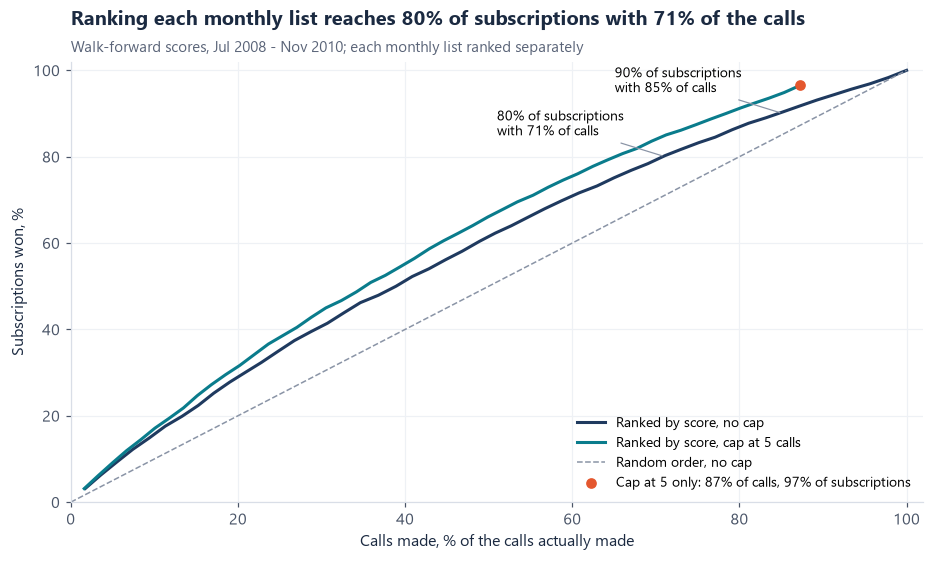

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(rk["calls_pct"] * 100, rk["subscriptions_pct"] * 100, color=PALETTE["navy"], label="Ranked by score, no cap")
ax.plot(rk_cap["calls_pct"] * 100, rk_cap["subscriptions_pct"] * 100, color=PALETTE["teal"], label="Ranked by score, cap at 5 calls")
ax.plot([0, 100], [0, 100], ls="--", color=PALETTE["grey"], lw=1, label="Random order, no cap")
cap5 = F.cap_effect(ev["campaign"], ev[F.TARGET], 5)
ax.scatter([100 * (1 - cap5["calls_saved_pct"])], [100 * cap5["subscriptions_kept_pct"]], color=PALETTE["coral"], zorder=3,
           label=f"Cap at 5 only: {1 - cap5['calls_saved_pct']:.0%} of calls, {cap5['subscriptions_kept_pct']:.0%} of subscriptions")
for tg in (0.8, 0.9):
    cp, _ = calls_for(rk, tg)
    ax.annotate(f"{tg:.0%} of subscriptions\nwith {cp:.0%} of calls", (cp * 100, tg * 100), xytext=(-110, 14), textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="-", color=PALETTE["grey"], lw=0.8))
ax.set(xlabel="Calls made, % of the calls actually made", ylabel="Subscriptions won, %", xlim=(0, 102), ylim=(0, 102))
ax.legend(loc="lower right", fontsize=9)
c80 = calls_for(rk, 0.8)[0]
headline(ax, f"Ranking each monthly list reaches 80% of subscriptions with {c80:.0%} of the calls",
         f"Walk-forward scores, {ev['call_month'].min():%b %Y} - {ev['call_month'].max():%b %Y}; each monthly list ranked separately")
_ = savefig(fig, "03-ranked-calling", FIG); plt.show()

Ranked calling reaches 80% of subscriptions with 71% of the calls, and 90% with 85%, against 80% and 90% in random
order: savings of 9 and 5 points. Within a single monthly list the ranking is weak (contact-weighted AUC 0.57), so
the score is better used to order the calls than to drop clients. The cap moves the whole curve left: about the
same subscriptions for fewer calls.

## 5. Which policy makes the most money?

Five policies on the same walk-forward contacts, valued at EUR 100 per subscription and EUR 5 per call.

In [7]:
pct = ev.groupby("call_month")["p"].rank(ascending=False, pct=True)
def run(mask, cap, margin=M, cost=C):
    calls = (ev["campaign"].clip(upper=cap) if cap else ev["campaign"]).where(mask, 0)
    subs = (ev[F.TARGET] == 1) & mask & ((ev["campaign"] <= cap) if cap else True)
    return pd.DataFrame({"period": ev["period"], "calls": calls, "subs": subs.astype(int), "net": subs * margin - calls * cost})
everyone = pd.Series(True, index=ev.index)
POLICIES = {"Call everyone, no cap (status quo)": (everyone, None), "Cap at 5 calls (published)": (everyone, 5),
            "EV floor: skip p < 5%": (~below, None), "EV floor + cap at 5": (~below, 5), "Top 80% of each list + cap at 5": (pct <= 0.8, 5)}
res = {k: run(m_, c_) for k, (m_, c_) in POLICIES.items()}
pol = pd.DataFrame({k: {"calls": r["calls"].sum(), "subscriptions": r["subs"].sum(), "subs per 100 calls": 100 * r["subs"].sum() / r["calls"].sum(),
                        "net value (EUR)": r["net"].sum()} for k, r in res.items()}).T
pol["vs status quo (EUR)"] = pol["net value (EUR)"] - pol.loc["Call everyone, no cap (status quo)", "net value (EUR)"]
by_period = pd.DataFrame({k: r.groupby("period", observed=True)["net"].sum() - res["Call everyone, no cap (status quo)"].groupby("period", observed=True)["net"].sum()
                          for k, r in res.items()}).T.drop(index="Call everyone, no cap (status quo)")
pol.round(1)

,calls,subscriptions,subs per 100 calls,net value (EUR),vs status quo (EUR)
"Call everyone, no cap (status quo)","71,564.0000","4,212.0000",5.9000,"63,380.0000",0.0000
Cap at 5 calls (published),"62,442.0000","4,065.0000",6.5000,"94,290.0000","30,910.0000"
EV floor: skip p < 5%,"55,082.0000","3,783.0000",6.9000,"102,890.0000","39,510.0000"
EV floor + cap at 5,"49,183.0000","3,683.0000",7.5000,"122,385.0000","59,005.0000"
Top 80% of each list + cap at 5,"49,732.0000","3,522.0000",7.1000,"103,540.0000","40,160.0000"


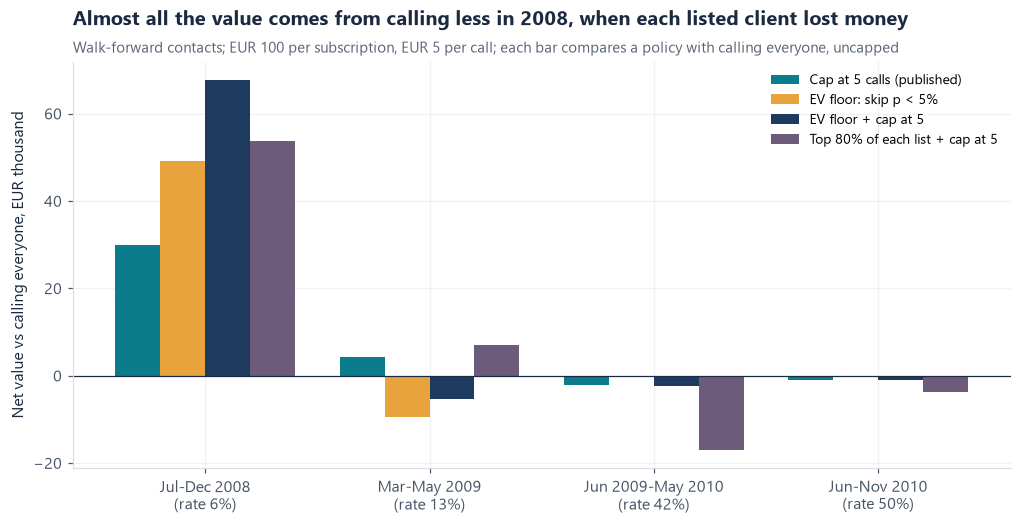

period,Jul-Dec 2008,Mar-May 2009,Jun 2009-May 2010,Jun-Nov 2010
Cap at 5 calls (published),29.8000,4.2000,-2.1000,-1.0000
EV floor: skip p < 5%,49.2000,-9.5000,-0.2000,0.0000
EV floor + cap at 5,67.6000,-5.3000,-2.4000,-1.0000
Top 80% of each list + cap at 5,53.8000,7.1000,-17.0000,-3.8000


In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
bp = by_period / 1000
xx = np.arange(bp.shape[1])
w = 0.8 / len(bp)
for i, (name, row) in enumerate(bp.iterrows()):
    ax.bar(xx + (i - (len(bp) - 1) / 2) * w, row.values, w, color=[PALETTE["teal"], PALETTE["amber"], PALETTE["navy"], PALETTE["purple"]][i], label=name)
ax.axhline(0, color=PALETTE["ink"], lw=0.8)
ax.set_xticks(xx, [f"{c}\n(rate {ev.loc[ev['period'] == c, F.TARGET].mean():.0%})" for c in bp.columns])
ax.set_ylabel("Net value vs calling everyone, EUR thousand"); ax.legend(loc="upper right", fontsize=9)
headline(ax, "Almost all the value comes from calling less in 2008, when each listed client lost money", "Walk-forward contacts; EUR 100 per subscription, EUR 5 per call; each bar compares a policy with calling everyone, uncapped")
_ = savefig(fig, "03-policy-value", FIG); plt.show()
(by_period / 1000).round(1)

* **Every policy beats calling everyone uncapped over the whole period.** Cap at 5: +EUR 30.9k. EV floor: +EUR 39.5k.
  Top 80% of each list plus cap: +EUR 40.2k. EV floor plus cap: +EUR 59.0k. The status quo nets EUR 63.4k from 71,564
  calls.
* **But the gains sit almost entirely in July-December 2008** (EUR 30-68k). That period's clients subscribed at 5.9%
  after an average of 2.8 calls, so at EUR 5 a call the average listed client lost money. Any policy that called less
  made money, targeted or not.
* **In 2009-10 calling less loses money.** With 42-50% conversion, every call pays. Dropping the bottom 20% of each
  list costs EUR 17k in June 2009-May 2010. The EV floor costs EUR 9.5k in spring 2009 by skipping clients the model
  wrongly scored low. The cap costs EUR 1-2k a period.
* **So the cap is the robust policy**: it gains in low-conversion periods and costs little in high ones. In this data,
  when to call mattered far more than whom to call.

In [9]:
sens = []
for margin in (50, 100, 150, 200):
    for cost in (2, 5, 10):
        be = cost / margin
        row = {"margin (EUR)": margin, "cost per call (EUR)": cost, "break-even p": be}
        base = run(everyone, None, margin, cost)["net"].sum()
        for k, (m_, c_) in {"cap 5": (everyone, 5), "EV floor + cap 5": (ev["p"] >= be, 5)}.items():
            row[k] = run(m_, c_, margin, cost)["net"].sum() - base
        sens.append(row)
sens = pd.DataFrame(sens)
(sens.set_index(["margin (EUR)", "cost per call (EUR)"])[["break-even p", "cap 5", "EV floor + cap 5"]] / [1, 1000, 1000]).round(2).rename(
    columns={"cap 5": "cap 5 vs status quo (EUR k)", "EV floor + cap 5": "EV floor + cap 5 vs status quo (EUR k)"})

break-even p  cap 5 vs status quo (EUR k)  EV floor + cap 5 vs status quo (EUR k)
margin (EUR) cost per call (EUR)                                                                                   
50           2                          0.0400                      10.8900                                 10.1400
             5                          0.1000                      38.2600                                151.4400
             10                         0.2000                      83.8700                                431.1500
100          2                          0.0200                       3.5400                                 -9.8600
             5                          0.0500                      30.9100                                 59.0000
             10                         0.1000                      76.5200                                302.8900
150          2                          0.0100                      -3.8100                                -21.1100
             5                          0.0300                      23.5600                                  7.4400
             10                         0.0700                      69.1700                                201.5500
200          2                          0.0100                     -11.1600                                -34.5000
             5                          0.0200                      16.2100                                -12.0400
             10                         0.0500                      61.8200                                118.0100

* The cap gains in 10 of 12 margin and cost combinations (+EUR 3.5k to +EUR 84k). It loses only when calls are cheap
  relative to the margin (EUR 2 a call with a EUR 150-200 margin: -EUR 4k to -EUR 11k).
* The EV floor plus cap swings from -EUR 35k to +EUR 431k. It is a bet that the probability level is right and that
  calls are expensive relative to the margin.
* Break-even moves from 1% to 20% across these assumptions, so the bank should pin down its real margin and call cost
  before any floor is used.

## 6. Recommendation

1. **Keep the attempt cap at five.** It reproduces the published result (15% fewer calls, 96% of subscriptions kept),
   adds EUR 30.9k over the walk-forward period under base assumptions, and gains under 10 of 12 cost assumptions.
2. **Size each campaign wave from the regime, using closed outcomes.** Track conversion per call in the first week of
   each wave. If the expected value per listed client (rate x margin - cost x calls per client) is negative, as it was
   throughout 2008, shrink the list. In this data that decision was worth more than any targeting.
3. **Use the score to order calls within a list, not to cut clients.** Within-list AUC is 0.57; ordering pays off when
   capacity runs out before the list does.
4. **Do not switch on an EV floor yet.** It needs calibrated probabilities, and they failed at both regime turns
   (2008-09 and spring 2010). Revisit once the monthly calibration check (predicted / observed within 0.8-1.25) has held
   for three months.
5. **Prove it with the holdout below before rolling out.**

## 7. How to prove it: a randomised holdout

Everything above is a back-test on the bank's own historical calling, which was not random: the model can only rank
clients the bank chose to call. Before rollout, run the policy as a controlled test.

* **Design:** randomise each monthly list at client level: 80% policy arm (score-ranked, cap at 5), 20% control arm
  (current practice). Randomise before scoring so both arms have the same mix.
* **Primary metric:** net value per listed client (subscriptions x margin - calls x cost). **Guardrails:** subscriptions
  per listed client (non-inferiority, -10% margin), complaints and opt-outs per 1,000 calls.
* **Sample size:** below, for the subscription rate per listed client at the two base rates seen in the data.

In [10]:
pw = NormalIndPower()
rows = []
for base in (0.10, 0.45):
    for rel in (0.10, 0.15, 0.20):
        es = proportion_effectsize(base, base * (1 - rel))
        n_ctrl = pw.solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=4.0, alternative="two-sided")
        rows.append({"base subscription rate": base, "detectable relative change": rel, "control clients": int(np.ceil(n_ctrl)),
                     "policy clients (4x)": int(np.ceil(4 * n_ctrl)), "total listed clients": int(np.ceil(5 * n_ctrl))})
power = pd.DataFrame(rows)
power

,base subscription rate,detectable relative change,control clients,policy clients (4x),total listed clients
0,0.1000,0.1000,8430,33719,42148
1,0.1000,0.1500,3655,14619,18274
2,0.1000,0.2000,2003,8012,10015
3,0.4500,0.1000,1185,4740,5925
4,0.4500,0.1500,523,2090,2612
5,0.4500,0.2000,291,1164,1455


At today's ~45% conversion, a 15% relative change in subscriptions per listed client needs about 2,600 listed
clients (520 in control). At 2010 list sizes of 130-310 a month that is close to ten months, so the test needs larger
lists or a 50/50 split, which needs fewer clients in total. At a 2008-style 10% base rate the same test needs 18,000.
Run to the planned sample: the interim check in the monitoring table is a harm check, not a reason to stop early on a
good number.

## 8. Monitoring

| What | How often | Trigger | Action |
|---|---|---|---|
| Predicted vs observed subscription rate (calibration) | Monthly, on the closed month | Ratio outside 0.8-1.25 | Re-estimate the intercept shift (already monthly) |
| AUC on the last closed month | Monthly | Below the lowest time-ordered fold AUC in notebook 02 | Refit and review features |
| PSI of each input and of the score | Monthly | > 0.25 on a client feature (macro inputs are expected to move) | Investigate the list source |
| Calls per subscription and share of clients hitting the cap | Weekly | Calls per subscription up 20% | Review cap and list size |
| Holdout arm results | Monthly, until the test reads out | Policy arm net value per client below control at the interim | Stop and review |

## 9. Limitations

* The back-test only re-orders clients the bank actually called. Clients it never called, and how they would respond,
  are outside the data. Only the holdout measures that.
* Margin and call cost are assumptions; the sensitivity table shows where the conclusion holds.
* `campaign` is the final number of calls. Under a new ranking, clients might need a different number of attempts.
* Propensity is not uplift: a high score can mean "would subscribe anyway". The holdout measures incremental effect.

In [11]:
report.update_metrics(METRICS, "03_contact_policy", {
    "cap5": {"calls_saved_pct": float(c5["calls_saved_pct"]), "subscriptions_kept_pct": float(c5["subscriptions_kept_pct"])},
    "walk_forward_rows": len(ev), "walk_forward_auc_pooled": float(evaluate.binary_metrics(ev[F.TARGET], ev["p"])["auc"]),
    "walk_forward_auc_within_month": float(within), "assumptions": {"margin": M, "cost_per_call": C},
    "calls_for_80pct": float(calls_for(rk, 0.8)[0]), "calls_for_90pct": float(calls_for(rk, 0.9)[0]),
    "policies": pol.to_dict(orient="index"), "policy_uplift_by_period": by_period.to_dict(orient="index"),
    "sensitivity": sens.to_dict(orient="records"), "holdout_power": power.to_dict(orient="records"),
})
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 12 s
